Prerequisites
The following installations are required for the completion of this tutorial. Make sure to install them if you haven't already.

Visual Studio Code

The Python extension for VS Code and Jupyter extension for VS Code from the Visual Studio Marketplace. For more details on installing extensions, see Extension Marketplace. Both extensions are published by Microsoft.

Miniconda with latest Python

You can download and install Miniconda from the official website: https://docs.conda.io/en/latest/miniconda.html

First install all the required frameworks and libraries:

python -m pip install pandas jupyter seaborn scikit-learn keras tensorflow

# Verify installations
python -m pip show pandas jupyter seaborn scikit-learn keras tensorflow


Crerate an anaconda virtual environment using the following command:

conda create -n myenv python=3.10 pandas jupyter seaborn scikit-learn keras tensorflow

Next, create a folder in a convenient location to serve as your VS Code workspace for the tutorial, name it hello_ds.

Open the project folder in VS Code by running VS Code and using the File > Open Folder command. You can safely trust opening the folder, since you created it.

Once VS Code launches, create the Jupyter notebook that will be used for the tutorial. Open the Command Palette (Ctrl+Shift+P) and select Create: New Jupyter Notebook.

Creating a new Jupyter Notebook

Note: Alternatively, from the VS Code File Explorer, you can use the New File icon to create a Notebook file named hello.ipynb.

Save the file as hello.ipynb using File > Save As....

After your file is created, you should see the open Jupyter notebook in the notebook editor. For additional information about native Jupyter notebook support, you can read the Jupyter Notebooks topic.

Now select Select Kernel at the top right of the notebook.
Choose the kernel corresponding to the environment you created earlier (myenv). This ensures that the notebook uses the correct Python environment with all the necessary packages installed.

You can verify that the correct kernel is selected by running the following code in a notebook cell:
```python
import sys
print(sys.executable)
```
The output should point to the Python executable within your myenv environment.

In [40]:
import sys
print(sys.executable)

c:\Users\student\AppData\Local\miniconda3\envs\myenv-jupyter\python.exe


Choose the Python environment you created above in which to run your kernel.

To manage your environment from VS Code's integrated terminal, open it up with (Ctrl+`). If your environment is not activated, you can do so as you would in your terminal (conda activate myenv)

You can verify that the environment is active by running:
```bash
conda info --envs
```
The active environment will be indicated with an asterisk (*).

PREAPRE THE DATA

https://hbiostat.org/data/repo/titanic.html 

To begin, download the Titanic data from hbiostat.org as a CSV file (download links in the upper right) named titanic3.csv and save it to the hello_ds folder that you created in the previous section.

If you haven't already opened the file in VS Code, open the hello_ds folder and the Jupyter notebook (hello.ipynb), by going to File > Open Folder.

Within your Jupyter notebook, begin by importing the pandas and numpy libraries, two common libraries used for manipulating data, and loading the Titanic data into a pandas DataFrame. To do so, copy the code below into the first cell of the notebook. For more guidance about working with Jupyter notebooks in VS Code, see the Working with Jupyter Notebooks documentation.

In [41]:
import pandas as pd
import numpy as np
data = pd.read_csv('titanic3.csv')

In [42]:
data.replace('?', np.nan, inplace= True)
data = data.astype({"age": np.float64, "fare": np.float64})


Now that the data is in good shape, you can use seaborn and matplotlib to view how certain columns of the dataset relate to survivability. Add the following code to the next cell in your notebook and run it to see the generated plots.

<Axes: xlabel='survived', ylabel='fare'>

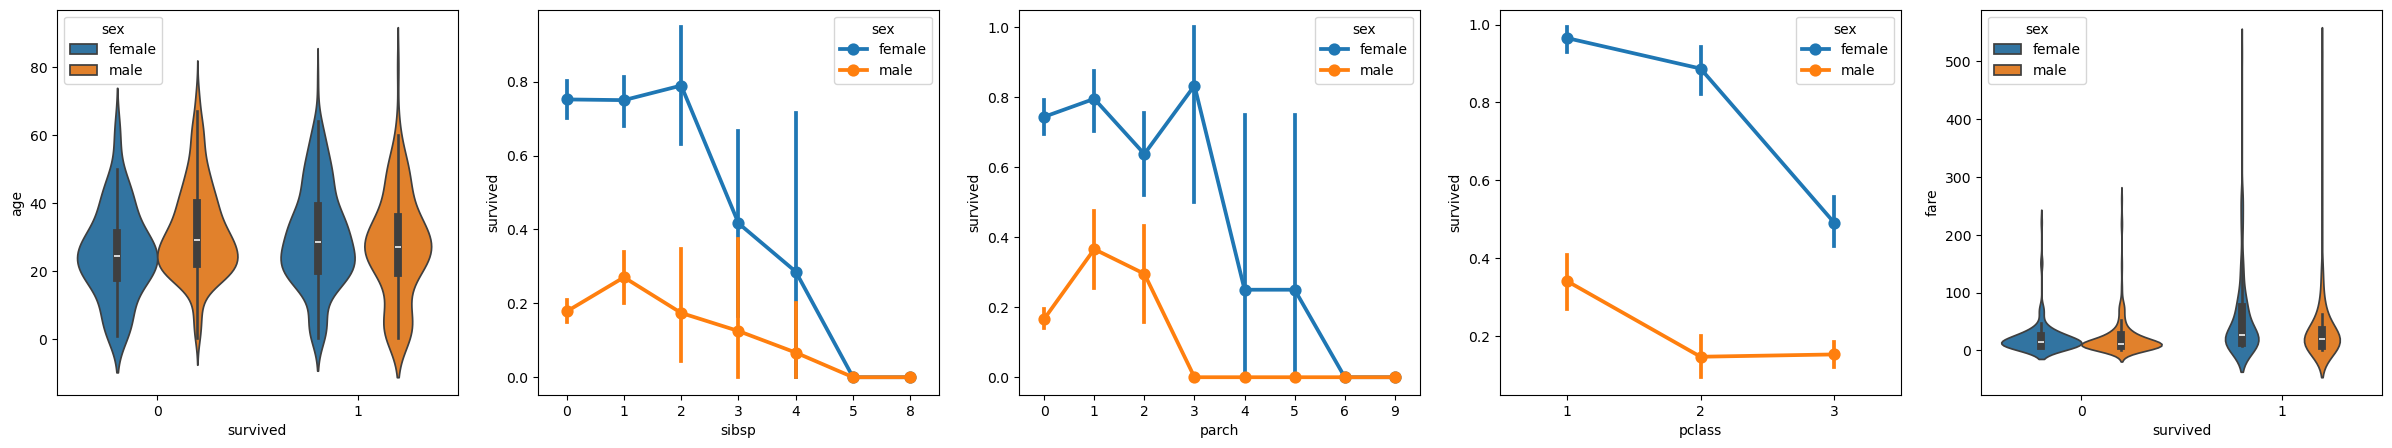

In [43]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axs = plt.subplots(ncols=5, figsize=(30,5))
sns.violinplot(x="survived", y="age", hue="sex", data=data, ax=axs[0])
sns.pointplot(x="sibsp", y="survived", hue="sex", data=data, ax=axs[1])
sns.pointplot(x="parch", y="survived", hue="sex", data=data, ax=axs[2])
sns.pointplot(x="pclass", y="survived", hue="sex", data=data, ax=axs[3])
sns.violinplot(x="survived", y="fare", hue="sex", data=data, ax=axs[4])


These graphs are helpful in seeing some of the relationships between survival and the input variables of the data, but it's also possible to use pandas to calculate correlations. To do so, all the variables used need to be numeric for the correlation calculation and currently gender is stored as a string. To convert those string values to integers, add and run the following code.

In [44]:
data.replace({'male': 1, 'female': 0}, inplace=True)


C:\Users\student\AppData\Local\Temp\ipykernel_12748\761646214.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data.replace({'male': 1, 'female': 0}, inplace=True)


Now, you can analyze the correlation between all the input variables to identify the features that would be the best inputs to a machine learning model. The closer a value is to 1, the higher the correlation between the value and the result. Use the following code to correlate the relationship between all variables and survival.

In [45]:
data.corr(numeric_only=True).abs()[["survived"]]


,survived
pclass,0.312469
survived,1.000000
sex,0.528693
age,0.055512
sibsp,0.027825
parch,0.082660
fare,0.244265
body,NaN


Looking at the correlation results, you'll notice that some variables like gender have a fairly high correlation to survival, while others like relatives (sibsp = siblings or spouse, parch = parents or children) seem to have little correlation.

Let's hypothesize that sibsp and parch are related in how they affect survivability, and group them into a new column called "relatives" to see whether the combination of them has a higher correlation to survivability. To do this, you will check if for a given passenger, the number of sibsp and parch is greater than 0 and, if so, you can then say that they had a relative on board.

Use the following code to create a new variable and column in the dataset called relatives and check the correlation again.

In [46]:
data['relatives'] = data.apply (lambda row: int((row['sibsp'] + row['parch']) > 0), axis=1)
data.corr(numeric_only=True).abs()[["survived"]]



,survived
pclass,0.312469
survived,1.000000
sex,0.528693
age,0.055512
sibsp,0.027825
parch,0.082660
fare,0.244265
body,NaN
relatives,0.201719


You'll notice that in fact when looked at from the standpoint of whether a person had relatives, versus how many relatives, there is a higher correlation with survival. With this information in hand, you can now drop from the dataset the low value sibsp and parch columns, as well as any rows that had NaN values, to end up with a dataset that can be used for training a model.

In [47]:
data = data[['sex', 'pclass','age','relatives','fare','survived']].dropna()


Note: Although age had a low direct correlation, it was kept because it seems reasonable that it might still have correlation in conjunction with other inputs like relatives or gender.

TRAIN and EVALUATE A MODEL

With the dataset ready, you can now begin creating a model. For this section, you'll use the scikit-learn library (as it offers some useful helper functions) to do pre-processing of the dataset, train a classification model to determine survivability on the Titanic, and then use that model with test data to determine its accuracy.

A common first step to training a model is to divide up the dataset into training and validation data. This allows you to use a portion of the data to train the model and a portion of the data to test the model. If you used all your data to train the model, you wouldn't have a way to estimate how well it would actually perform against data the model hasn't yet seen. A benefit of the scikit-learn library is that it provides a method specifically for splitting a dataset into training and test data.

Add and run a cell with the following code to the notebook to split up the data.

In [48]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(data[['sex','pclass','age','relatives','fare']], data.survived, test_size=0.2, random_state=0)

Next, you'll normalize the inputs such that all features are treated equally. For example, within the dataset the values for age range from ~0-100, while gender is only a 1 or 0. By normalizing all the variables, you can ensure that the ranges of values are all the same. Use the following code in a new code cell to scale the input values.

In [49]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(x_train)
X_test = sc.transform(x_test)


There are many different machine learning algorithms that you could choose from to model the data. The scikit-learn library also provides support for many of them and a chart to help select the one that's right for your scenario. For now, use the Naïve Bayes algorithm, a common algorithm for classification problems. Add a cell with the following code to create and train the algorithm.

In [50]:
from sklearn.naive_bayes import GaussianNB
model = GaussianNB()
model.fit(X_train, y_train)


,priors,None
,var_smoothing,1e-09


With a trained model, you can now try it against the test data set that was held back from training. Add and run the following code to predict the outcome of the test data and calculate the accuracy of the model.

In [51]:
from sklearn import metrics
predict_test = model.predict(X_test)
print(metrics.accuracy_score(y_test, predict_test))



0.7464114832535885


Looking at the result of the test data, you'll see that the trained algorithm had a ~75% success rate at estimating survival correctly. This indicates that the model is reasonably effective at predicting survival based on the selected features, though there is still room for improvement.

Let us now create infographics and confusion matrices to better understand the performance of our model. Infographics can help visualize the distribution of predictions, while confusion matrices provide a detailed breakdown of true positives, true negatives, false positives, and false negatives.

[[106  22]
 [ 31  50]]
              precision    recall  f1-score   support

           0       0.77      0.83      0.80       128
           1       0.69      0.62      0.65        81

    accuracy                           0.75       209
   macro avg       0.73      0.72      0.73       209
weighted avg       0.74      0.75      0.74       209



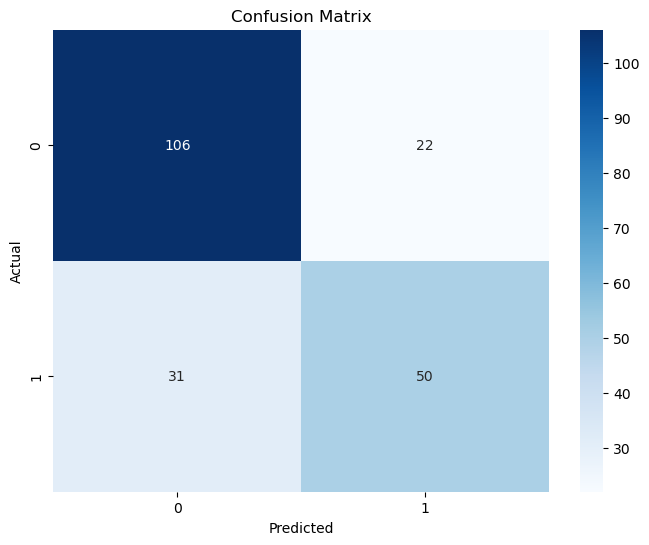

In [52]:
predict_test_binary = (predict_test.ravel() >= 0.5).astype(int)
print(metrics.confusion_matrix(y_test, predict_test_binary))
print(metrics.classification_report(y_test, predict_test_binary))

# Optionally, visualize the confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(metrics.confusion_matrix(y_test, predict_test_binary), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

END OF MODEL EVALUATION

(Optional) Use a neural network
A neural network is a model that uses weights and activation functions, modeling aspects of human neurons, to determine an outcome based on provided inputs. Unlike the machine learning algorithm you looked at previously, neural networks are a form of deep learning wherein you don't need to know an ideal algorithm for your problem set ahead of time. It can be used for many different scenarios and classification is one of them. For this section, you'll use the Keras library with TensorFlow to construct the neural network, and explore how it handles the Titanic dataset.

The first step is to import the required libraries and to create the model. In this case, you'll use a Sequential neural network, which is a layered neural network wherein there are multiple layers that feed into each other in sequence.

In [53]:
from keras.models import Sequential
from keras.layers import Dense

model = Sequential()


After defining the model, the next step is to add the layers of the neural network. For now, let's keep things simple and just use three layers. Add the following code to create the layers of the neural network.

In [54]:
model.add(Dense(5, kernel_initializer = 'uniform', activation = 'relu', input_dim = 5))
model.add(Dense(5, kernel_initializer = 'uniform', activation = 'relu'))
model.add(Dense(1, kernel_initializer = 'uniform', activation = 'sigmoid'))


c:\Users\student\AppData\Local\miniconda3\envs\myenv-jupyter\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


The first layer will be set to have a dimension of 5, since you have five inputs: sex, pclass, age, relatives, and fare.
The last layer must output 1, since you want a 1-dimensional output indicating whether a passenger would survive.
The middle layer was kept at 5 for simplicity, although that value could have been different.
The rectified linear unit (relu) activation function is used as a good general activation function for the first two layers, while the sigmoid activation function is required for the final layer as the output you want (of whether a passenger survives or not) needs to be scaled in the range of 0-1 (the probability of a passenger surviving).

You can also look at the summary of the model you built with this line of code:

In [55]:
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 5)              │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 5)              │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66 (264.00 B)

 Trainable params: 66 (264.00 B)

 Non-trainable params: 0 (0.00 B)

Generate confusion matrix and classification report for the test set.

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
0.4784688995215311
[[34 94]
 [15 66]]
              precision    recall  f1-score   support

           0       0.69      0.27      0.38       128
           1       0.41      0.81      0.55        81

    accuracy                           0.48       209
   macro avg       0.55      0.54      0.47       209
weighted avg       0.58      0.48      0.45       209



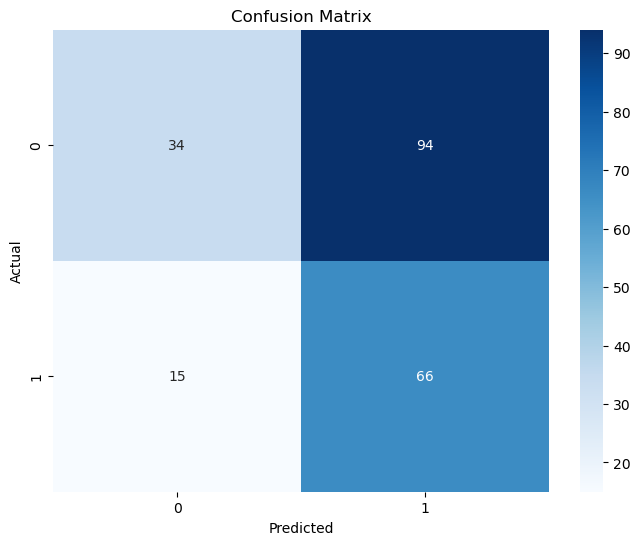

In [56]:
from sklearn import metrics
predict_test = model.predict(X_test)
print(metrics.accuracy_score(y_test, (predict_test.ravel() >= 0.5).astype(int)))
predict_test_binary = (predict_test.ravel() >= 0.5).astype(int)
print(metrics.confusion_matrix(y_test, predict_test_binary))
print(metrics.classification_report(y_test, predict_test_binary))

# Optionally, visualize the confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(metrics.confusion_matrix(y_test, predict_test_binary), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [57]:
model.compile(optimizer="adam", loss='binary_crossentropy', metrics=['accuracy'])
model.fit(X_train, y_train, batch_size=32, epochs=50)


Epoch 1/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5730 - loss: 0.6924   
Epoch 2/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5861 - loss: 0.6907 
Epoch 3/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5861 - loss: 0.6879 
Epoch 4/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5861 - loss: 0.6825 
Epoch 5/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6746 - loss: 0.6723 
Epoch 6/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7644 - loss: 0.6562 
Epoch 7/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7727 - loss: 0.6346 
Epoch 8/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7715 - loss: 0.6086 
Epoch 9/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7751 - loss: 0.5804 
Epoch 10/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7739 - loss: 0.5541 
Epoch 11/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7727 - loss: 0.5332 
Epoch 12/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy

Now that the model is built and trained, we can see how it works against the test data.

In [58]:
y_pred = np.rint(model.predict(X_test).flatten())
print(metrics.accuracy_score(y_test, y_pred))
print(metrics.classification_report(y_test, y_pred))
print(metrics.log_loss(y_test, y_pred))


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
0.8038277511961722
              precision    recall  f1-score   support

           0       0.81      0.88      0.85       128
           1       0.79      0.68      0.73        81

    accuracy                           0.80       209
   macro avg       0.80      0.78      0.79       209
weighted avg       0.80      0.80      0.80       209

3.1274536425607193


Similar to the training, you'll notice that you now have 80% accuracy in predicting survival of passengers. Using this simple neural network, the result is better than the 75% accuracy from the Naive Bayes Classifier tried previously.

Understanding various metrics used on this page:
1. confusion metrics and other charts https://github.com/ShahabName/applied-ai-training-labs/blob/main/labs/student/02-Google-AI-Studio/04-GAIS-Lab-BigQuery-ML/confusion-matrix-pr-roc-tutorial.html
2. Evaluation metrics and their explanations can be found at: https://github.com/ShahabName/applied-ai-training-labs/blob/main/labs/student/02-Google-AI-Studio/04-GAIS-Lab-BigQuery-ML/evaluation-metrics-tutorial.html
3. Training Metris https://github.com/ShahabName/applied-ai-training-labs/blob/main/labs/student/02-Google-AI-Studio/04-GAIS-Lab-BigQuery-ML/training-metrics-tutorial.html



In [61]:
from html import escape
import re
from urllib.request import urlopen
from IPython.display import HTML, display

url = (
    "https://raw.githubusercontent.com/ShahabName/"
    "applied-ai-training-labs/main/labs/student/"
    "02-Google-AI-Studio/04-GAIS-Lab-BigQuery-ML/"
    "confusion-matrix-pr-roc-tutorial.html"
)

with urlopen(url) as response:
    page = response.read().decode("utf-8")

# Resolve the tutorial's relative image paths against its GitHub location.
base_url = url.rsplit("/", 1)[0] + "/"
page, count = re.subn(
    r"(<head\b[^>]*>)",
    lambda match: match.group(1) + f'<base href="{escape(base_url, quote=True)}">',
    page,
    count=1,
    flags=re.IGNORECASE,
)
if count != 1:
    raise ValueError("The HTML page does not contain a <head> element.")

display(HTML(
    f'<iframe srcdoc="{escape(page, quote=True)}" '
    'width="100%" height="900" sandbox '
    'style="border: 1px solid #ccc;"></iframe>'
))

c:\Users\student\AppData\Local\miniconda3\envs\myenv-jupyter\lib\site-packages\IPython\core\display.py:475: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


In [62]:
from html import escape
import re
from urllib.request import urlopen
from IPython.display import HTML, display

url = (
    "https://raw.githubusercontent.com/ShahabName/"
    "applied-ai-training-labs/main/labs/student/"
    "02-Google-AI-Studio/04-GAIS-Lab-BigQuery-ML/"
    "evaluation-metrics-tutorial.html"
)

with urlopen(url) as response:
    page = response.read().decode("utf-8")

# Resolve the tutorial's relative image paths against its GitHub location.
base_url = url.rsplit("/", 1)[0] + "/"
page, count = re.subn(
    r"(<head\b[^>]*>)",
    lambda match: match.group(1) + f'<base href="{escape(base_url, quote=True)}">',
    page,
    count=1,
    flags=re.IGNORECASE,
)
if count != 1:
    raise ValueError("The HTML page does not contain a <head> element.")

display(HTML(
    f'<iframe srcdoc="{escape(page, quote=True)}" '
    'width="100%" height="900" sandbox '
    'style="border: 1px solid #ccc;"></iframe>'
))

c:\Users\student\AppData\Local\miniconda3\envs\myenv-jupyter\lib\site-packages\IPython\core\display.py:475: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")
